In [613]:
file_string = open('names.txt','r').read()
names = file_string.split('\n')

In [614]:
names

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn',
 'abigail',
 'emily',
 'elizabeth',
 'mila',
 'ella',
 'avery',
 'sofia',
 'camila',
 'aria',
 'scarlett',
 'victoria',
 'madison',
 'luna',
 'grace',
 'chloe',
 'penelope',
 'layla',
 'riley',
 'zoey',
 'nora',
 'lily',
 'eleanor',
 'hannah',
 'lillian',
 'addison',
 'aubrey',
 'ellie',
 'stella',
 'natalie',
 'zoe',
 'leah',
 'hazel',
 'violet',
 'aurora',
 'savannah',
 'audrey',
 'brooklyn',
 'bella',
 'claire',
 'skylar',
 'lucy',
 'paisley',
 'everly',
 'anna',
 'caroline',
 'nova',
 'genesis',
 'emilia',
 'kennedy',
 'samantha',
 'maya',
 'willow',
 'kinsley',
 'naomi',
 'aaliyah',
 'elena',
 'sarah',
 'ariana',
 'allison',
 'gabriella',
 'alice',
 'madelyn',
 'cora',
 'ruby',
 'eva',
 'serenity',
 'autumn',
 'adeline',
 'hailey',
 'gianna',
 'valentina',
 'isla',
 'eliana',
 'quinn',
 'nevaeh',
 'ivy',
 'sadie',
 'piper',
 'lydia',
 'alexa',
 'josephine',
 'emery',
 'julia'

In [615]:
len(names)

32033

In [616]:
characters_list = sorted(set(list(file_string)))
characters_list.remove('\n')
characters_list.append('.')
characters_list

['a',
 'b',
 'c',
 'd',
 'e',
 'f',
 'g',
 'h',
 'i',
 'j',
 'k',
 'l',
 'm',
 'n',
 'o',
 'p',
 'q',
 'r',
 's',
 't',
 'u',
 'v',
 'w',
 'x',
 'y',
 'z',
 '.']

In [617]:
import torch
import torch.nn as nn

n = 4 #context size. n-1 is input context size and 1 is the output
input_context_size = n - 1
embed_dimensions = 50
no_of_characters = len(characters_list)
lookup_matrix = torch.randn((no_of_characters, embed_dimensions), requires_grad = True)
char_to_idx = {c: i for i, c in enumerate(characters_list)}
learning_rate = 0.01

lookup_matrix.shape
lookup_matrix[0]

tensor([ 1.5205,  1.3513,  0.0805, -0.0539, -0.2970, -1.0065, -0.2209,  0.0464,
         0.3209, -0.4272, -1.6220,  1.2227, -0.6826, -0.6020, -0.7649, -0.9482,
        -0.5204, -0.2379, -0.1442,  0.1959, -0.5346, -0.2315, -0.2554,  1.5980,
         0.9049, -0.5752, -0.3984,  0.8060, -0.1448,  1.8646,  0.2404, -0.0494,
        -0.3336, -1.1548,  0.7895, -0.8250, -1.2559, -1.2952, -0.5800, -0.6019,
        -0.6116,  1.9077, -1.6461,  0.8850, -0.2884,  1.1639,  0.5596, -0.2491,
        -1.0642, -0.6798], grad_fn=<SelectBackward0>)

In [618]:
torch.cat((lookup_matrix[0], lookup_matrix[0], lookup_matrix[0]))

tensor([ 1.5205,  1.3513,  0.0805, -0.0539, -0.2970, -1.0065, -0.2209,  0.0464,
         0.3209, -0.4272, -1.6220,  1.2227, -0.6826, -0.6020, -0.7649, -0.9482,
        -0.5204, -0.2379, -0.1442,  0.1959, -0.5346, -0.2315, -0.2554,  1.5980,
         0.9049, -0.5752, -0.3984,  0.8060, -0.1448,  1.8646,  0.2404, -0.0494,
        -0.3336, -1.1548,  0.7895, -0.8250, -1.2559, -1.2952, -0.5800, -0.6019,
        -0.6116,  1.9077, -1.6461,  0.8850, -0.2884,  1.1639,  0.5596, -0.2491,
        -1.0642, -0.6798,  1.5205,  1.3513,  0.0805, -0.0539, -0.2970, -1.0065,
        -0.2209,  0.0464,  0.3209, -0.4272, -1.6220,  1.2227, -0.6826, -0.6020,
        -0.7649, -0.9482, -0.5204, -0.2379, -0.1442,  0.1959, -0.5346, -0.2315,
        -0.2554,  1.5980,  0.9049, -0.5752, -0.3984,  0.8060, -0.1448,  1.8646,
         0.2404, -0.0494, -0.3336, -1.1548,  0.7895, -0.8250, -1.2559, -1.2952,
        -0.5800, -0.6019, -0.6116,  1.9077, -1.6461,  0.8850, -0.2884,  1.1639,
         0.5596, -0.2491, -1.0642, -0.67

In [619]:
# Neural network weights
hidden_layer_size = 200
W1 = torch.randn((embed_dimensions*input_context_size, hidden_layer_size), requires_grad = True)
b1 = torch.randn(hidden_layer_size, requires_grad = True)

# Since we are scaling W2 and b2 by 0.01, that operation turns them into non-leaf nodes.
# So, we first scale and then say `requires_grad = True`
W2 = torch.randn((hidden_layer_size, no_of_characters)) * 0.01
W2.requires_grad = True
b2 = torch.randn(no_of_characters) * 0.01
b2.requires_grad = True

# Another way to do that is
# W2 = torch.randn((hidden_layer_size, no_of_characters), requires_grad=True)
# with torch.no_grad():
#    W2 *= 0.01

parameters = [lookup_matrix, W1, b1, W2, b2]

print(f"{W1.shape} {W2.shape}")

torch.Size([150, 200]) torch.Size([200, 27])


In [620]:
def forward_pass(input_context):
    input_context_embeddings = torch.cat(torch.unbind(lookup_matrix[[char_to_idx[c] for c in input_context]]))
    W1_out = torch.tanh(input_context_embeddings @ W1 + b1)
    W2_out = W1_out @ W2 + b2

    logits = W2_out - W2_out.max(dim=-1, keepdim=True).values
    counts = logits.exp()
    probs = counts / counts.sum(dim=-1, keepdim=True)

    ### DEBUG START
    print(f"W1_out={W1_out}")
    #print(f"\n W1={W1}\n b1={b1}\n W2={W2}\n b2={b2}")
    #print(f"\n input_context_embeddings={input_context_embeddings}\n W1_out={W1_out}\n W2_out={W2_out}\n logits={logits}\n counts={counts}\n")

    ### DEBUG END

    return probs

In [621]:
def calculate_loss (probs, correct_char):
    correct_char_prob = probs[char_to_idx[correct_char]]
    ll = torch.log(correct_char_prob)
    nll = -ll

    return nll

In [622]:
def gradient_descent (loss):
    for p in parameters:
        p.grad = None

    loss.backward()

    ### DEBUG CODE START
    #for i, p in enumerate(parameters):
    #    print(f"param {i} grad norm: {p.grad.norm().item():.4f}")
    ### DEBUG CODE END

    for i, p in zip(range(len(parameters)), parameters):
        p.data += -(learning_rate * p.grad)

In [623]:
import matplotlib.pyplot as plt

def visualize (losses):
    plt.figure(figsize=(10, 5))
    plt.plot(losses)
    plt.xlabel("Name (training step)")
    plt.ylabel("Mean loss")
    plt.title("Loss over training")
    plt.grid(True)

In [624]:
def train ():
    training_set = list(names[0:100])
    losses = []

    ### DEBUG CODE START
    #print(f"char_to_idx{char_to_idx}")
    ### DEBUG CODE END
    
    for name in training_set:
        transformed_name = ("."*input_context_size) + name + "."
        idx = 0
        batched_loss = []
        while True:
            input_chars = list(transformed_name[idx: (idx + input_context_size)])
            correct_output_char = transformed_name[idx + input_context_size]

            probs = forward_pass(input_chars)

            ### DEBUG CODE START
            #print(f"probs={probs}")
            #print(f"correct_char={correct_output_char}")
            #if probs[char_to_idx[correct_output_char]] == 0:
            #   break
            ### DEBUG CODE END
            
            loss = calculate_loss(probs, correct_output_char)
            batched_loss.append(loss)
            #print(f"loss: {loss}")
            #gradient_descent(loss)
            
            if (correct_output_char == '.'):
                break
            idx+=1

        losses.append(torch.stack(batched_loss).mean().item())
        gradient_descent(torch.stack(batched_loss).mean())

    visualize(losses)
        

W1_out=tensor([ 1.0000,  1.0000,  1.0000, -1.0000, -1.0000, -1.0000, -1.0000,  1.0000,
         0.9998, -1.0000,  1.0000,  1.0000, -1.0000, -0.8744,  1.0000, -1.0000,
         1.0000,  1.0000, -1.0000,  1.0000, -1.0000, -1.0000,  1.0000,  1.0000,
         1.0000,  1.0000, -1.0000, -0.9488, -1.0000,  1.0000,  1.0000,  0.5798,
         1.0000,  1.0000, -1.0000, -1.0000, -0.8857, -1.0000,  1.0000,  1.0000,
         1.0000, -0.9720,  1.0000,  0.9985, -1.0000,  1.0000,  1.0000,  0.8922,
         1.0000, -0.9886,  1.0000,  0.2058,  1.0000, -0.9410,  1.0000, -0.9667,
         1.0000,  1.0000, -0.6158,  1.0000, -1.0000,  1.0000, -1.0000, -1.0000,
         1.0000,  1.0000,  1.0000, -0.9354,  1.0000,  1.0000, -1.0000, -1.0000,
         1.0000, -1.0000,  0.0756, -1.0000, -0.9975, -0.9984, -0.9915,  1.0000,
        -0.9604, -0.0448,  0.9091,  1.0000, -0.4191, -1.0000, -1.0000,  1.0000,
         1.0000,  0.9907, -1.0000,  1.0000, -1.0000, -0.9999,  1.0000,  0.9999,
         1.0000,  1.0000, -1.0000

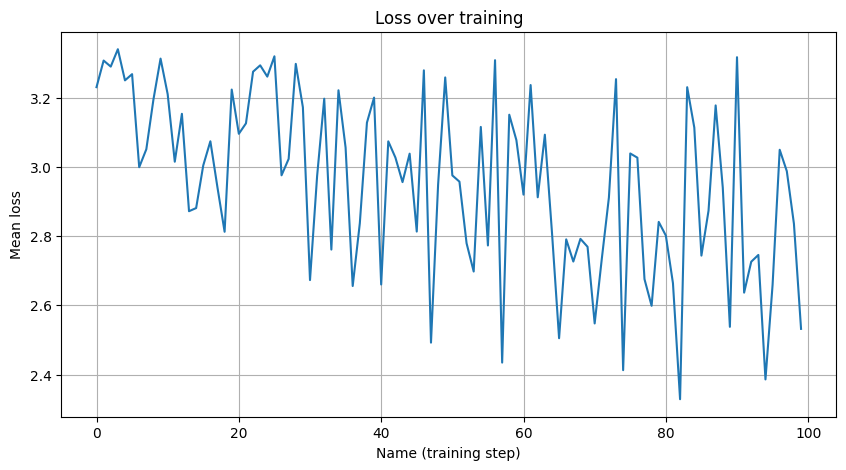

In [625]:
train()
plt.show()